# Scene-based Complementary Fashion Recommendation on Pinterest

**Question.** A user is looking at an outfit photo (a *scene*). Which fashion *products* go with it?
This is the "Complete the Look" problem from Pinterest. A new pin has no interaction history,
so we have to recommend from **visual content**. In other words, this is a cold-start recommendation problem.

**Outline**
1. Predictive task and evaluation
2. Dataset, preprocessing and exploratory analysis
3. Models: from course baselines to visually-aware BPR
4. Evaluation and results
5. Related work

## 1. Predictive task

Given a scene $s$ and a product category $c$, rank candidate products of category $c$
so that the product that actually appears in $s$ is ranked first.

* **Input:** the scene image (with the target product **greyed out**, so the model cannot just "see the answer"), plus the candidate product images.
* **Output:** a compatibility score $f(s, p)$.
* **Objective:** Bayesian Personalized Ranking (BPR): $\max \sum \ln \sigma(f(s,p^+) - f(s,p^-))$.
* **Evaluation:** each test (scene, product) pair is ranked against **99 negatives from the same category**.
  We report AUC, Hit@10 and NDCG@10.
  Same-category negatives make the task about *style compatibility*, not about guessing the category.
* **Baselines:** Random, Popularity, BPR-MF (collaborative filtering), and zero-shot CLIP similarity.
* **Validity:** we split **by scene**, so every test scene is unseen during training (realistic cold start).
  Hyper-parameters are chosen on a separate validation split, and we break results down by category and by product popularity.

In [1]:
import json, os, random, collections, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DATA = 'data'
plt.rcParams['figure.dpi'] = 110

## 2. Dataset and exploratory analysis

**Source.** The Pinterest Fashion Compatibility dataset (STL-Dataset) from Kang et al., *Complete the Look*, CVPR 2019,
https://github.com/kang205/STL-Dataset.
It comes from Pinterest's "Shop the Look" annotations. Each record says that a product appears in a scene photo, and gives its bounding box.
Images are identified by a signature and can be downloaded from Pinterest's CDN.

**Preprocessing** (done once in `prepare_data.py`; this notebook only loads the cached outputs):
1. Download all scene and product images (236px wide).
2. Encode every image with a pretrained **CLIP ViT-B/32** image encoder. The embeddings are L2-normalised 512-d vectors.
3. For every (scene, product) pair, encode the scene again with **that product's bounding box greyed out**. This is the query the model sees.

In [2]:
pairs = pd.DataFrame([json.loads(l) for l in open(f'{DATA}/fashion.json')])
cat_full = json.load(open(f'{DATA}/fashion-cat.json'))
pairs['category'] = pairs['product'].map(lambda p: cat_full[p].split('|')[-1])
pairs.head()

,product,scene,bbox,category
0,0027e30879ce3d87f82f699f148bff7e,cdab9160072dd1800038227960ff6467,"[0.434097, 0.859363, 0.560254, 1.0]",Shoes
1,0027e30879ce3d87f82f699f148bff7e,14f59334af4539132981b1324a731067,"[0.175269, 0.527773, 0.621485, 0.924899]",Shoes
2,0027e30879ce3d87f82f699f148bff7e,e7d32df9f45b691afc580808750f73ca,"[0.588666, 0.638503, 0.750647, 0.761368]",Shoes
3,0027e30879ce3d87f82f699f148bff7e,c0be585ed21b1a6c6dc9559ebe007ede,"[0.276699, 0.757741, 0.400485, 0.876138]",Shoes
4,002a6586b8381b5efd39410657630b44,67ed2a06be8a26dc63d7a04d4e1a135f,"[0.154545, 0.144809, 0.809091, 0.784153]","Handbags, Wallets & Cases"


In [3]:
n_s, n_p = pairs.scene.nunique(), pairs['product'].nunique()
stats = pd.Series({
    'scene-product pairs': len(pairs),
    'scenes': n_s,
    'products': n_p,
    'categories': pairs.category.nunique(),
    'density': len(pairs) / (n_s * n_p),
    'products per scene (mean)': len(pairs) / n_s,
    'scenes per product (mean)': len(pairs) / n_p,
    'products seen in only 1 scene': (pairs['product'].value_counts() == 1).mean(),
})
stats.to_frame('value')

,value
scene-product pairs,72198.000000
scenes,29438.000000
products,38111.000000
categories,10.000000
density,0.000064
products per scene (mean),2.452544
scenes per product (mean),1.894414
products seen in only 1 scene,0.702448


The interaction matrix is extremely sparse (density about $6\times10^{-5}$), and **70% of products appear in only one scene**.
Pure ID-based collaborative filtering has very little signal to work with here. This is the main motivation for using visual features.

Note: the released file has 72,198 pairs and 29,438 scenes. That is fewer than the 93,274 pairs listed on the dataset page; we use the released file as-is.

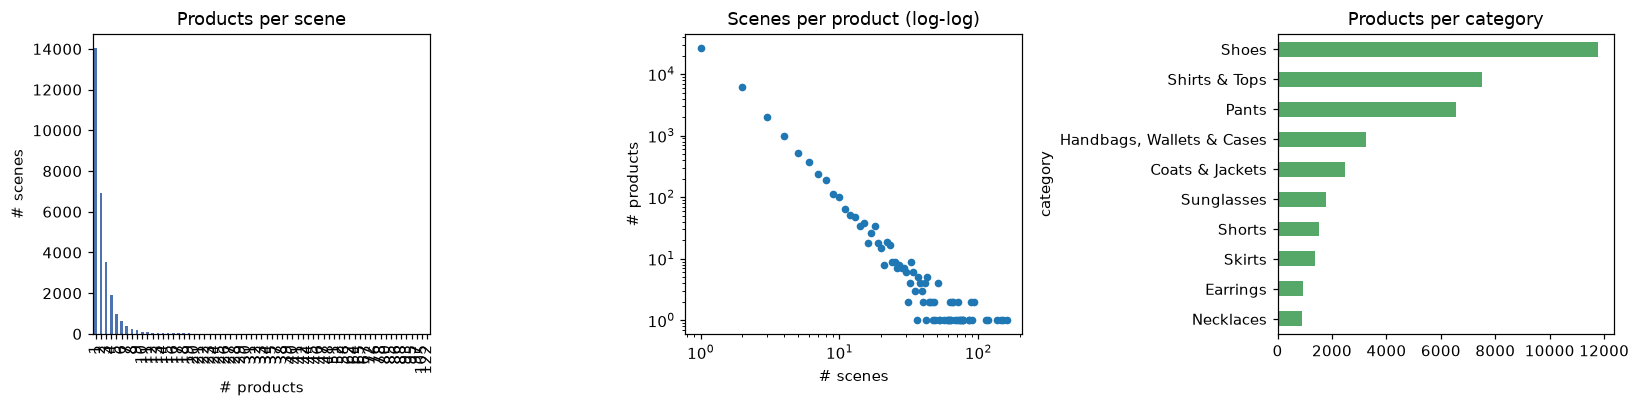

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
pairs.groupby('scene').size().value_counts().sort_index().plot.bar(ax=ax[0], color='#4C72B0')
ax[0].set(title='Products per scene', xlabel='# products', ylabel='# scenes')
vc = pairs['product'].value_counts().value_counts().sort_index()
ax[1].loglog(vc.index, vc.values, 'o', ms=4)
ax[1].set(title='Scenes per product (log-log)', xlabel='# scenes', ylabel='# products')
pairs.drop_duplicates('product').category.value_counts().plot.barh(ax=ax[2], color='#55A868')
ax[2].set(title='Products per category'); ax[2].invert_yaxis()
plt.tight_layout(); plt.show()

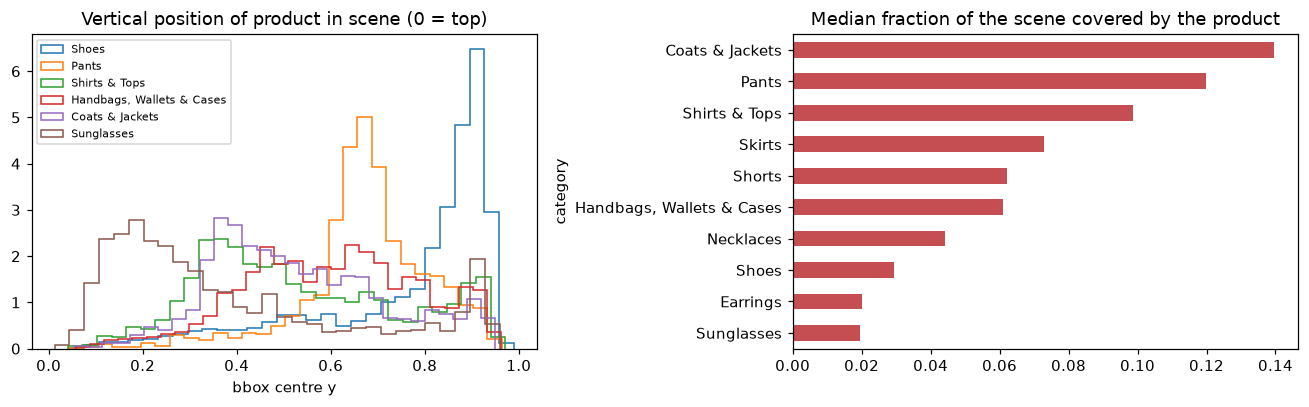

In [5]:
bb = np.array(pairs.bbox.tolist())
pairs['bbox_area'] = (bb[:, 2] - bb[:, 0]) * (bb[:, 3] - bb[:, 1])
pairs['bbox_cy'] = (bb[:, 1] + bb[:, 3]) / 2
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for c in pairs.category.value_counts().index[:6]:
    ax[0].hist(pairs.loc[pairs.category == c, 'bbox_cy'], bins=30, histtype='step', label=c, density=True)
ax[0].set(title='Vertical position of product in scene (0 = top)', xlabel='bbox centre y'); ax[0].legend(fontsize=7)
pairs.groupby('category').bbox_area.median().sort_values().plot.barh(ax=ax[1], color='#C44E52')
ax[1].set(title='Median fraction of the scene covered by the product')
plt.tight_layout(); plt.show()

The bounding boxes follow the body layout: sunglasses and earrings near the top, tops in the middle, pants and shoes at the bottom.
Products usually cover only a small part of the scene, so most of the scene (the rest of the outfit) is still visible after masking.

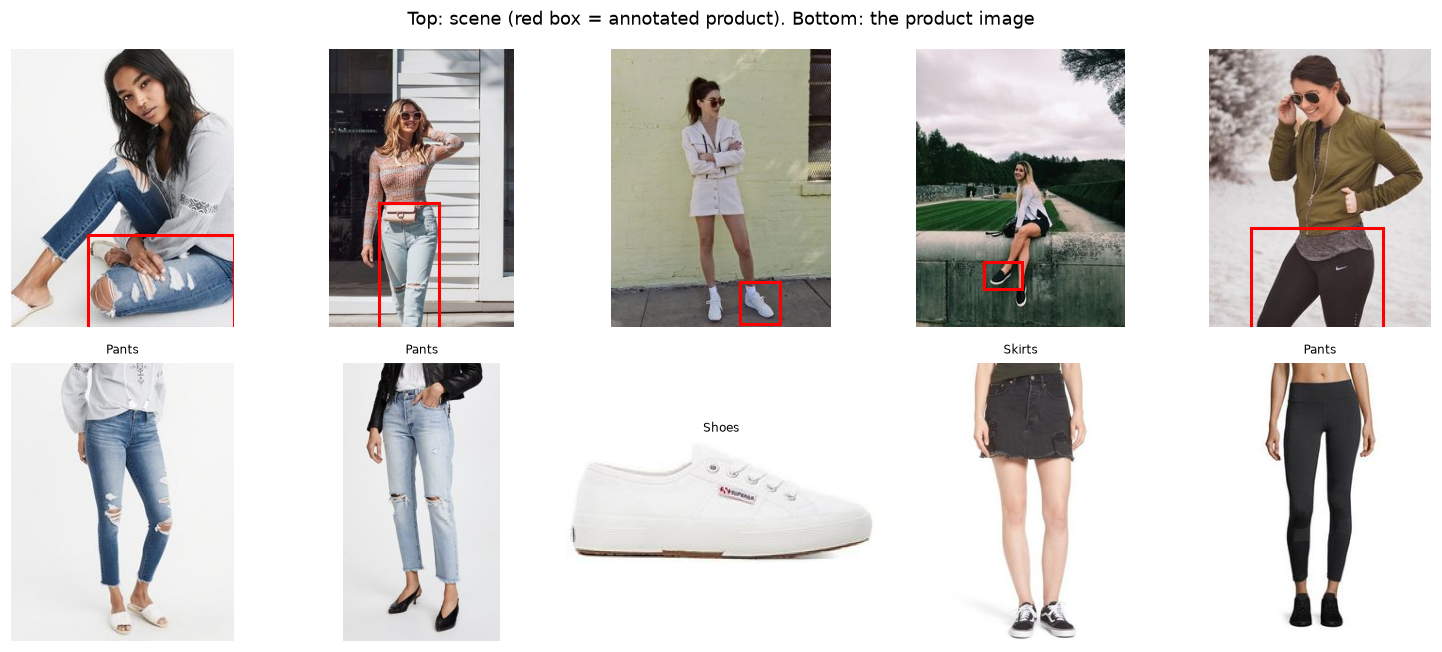

In [6]:
def img(sig):
    path = f'{DATA}/images/{sig}.jpg'
    return Image.open(path).convert('RGB') if os.path.exists(path) else Image.new('RGB', (236, 236), 'white')

def show_pair(ax_s, ax_p, row):
    im = img(row.scene); w, h = im.size; l, t, r, b = row.bbox
    ax_s.imshow(im); ax_s.add_patch(plt.Rectangle((l*w, t*h), (r-l)*w, (b-t)*h, fill=False, ec='red', lw=2))
    ax_p.imshow(img(row['product'])); ax_p.set_title(row.category, fontsize=8)
    ax_s.axis('off'); ax_p.axis('off')

sample = pairs.sample(5, random_state=1)
fig, ax = plt.subplots(2, 5, figsize=(14, 6))
for i, (_, row) in enumerate(sample.iterrows()):
    show_pair(ax[0, i], ax[1, i], row)
plt.suptitle('Top: scene (red box = annotated product). Bottom: the product image'); plt.tight_layout(); plt.show()

In [7]:
missing = json.load(open(f'{DATA}/missing_images.json'))
idx = json.load(open(f'{DATA}/feat_index.json'))
P_FEAT = np.load(f'{DATA}/feat_product.npy').astype(np.float32)
S_FULL = np.load(f'{DATA}/feat_scene.npy').astype(np.float32)
S_MASK = np.load(f'{DATA}/feat_scene_masked.npy').astype(np.float32)   # one row per pair
pid = {p: i for i, p in enumerate(idx['products'])}
sid = {s: i for i, s in enumerate(idx['scenes'])}
pairs['p'] = pairs['product'].map(pid); pairs['s'] = pairs.scene.map(sid); pairs['row'] = np.arange(len(pairs))
print(f'images missing: {len(missing)} / {n_s + n_p}')
print('feature shapes:', P_FEAT.shape, S_FULL.shape, S_MASK.shape)

images missing: 6 / 67549
feature shapes: (38111, 512) (29438, 512) (72198, 512)


### Train / validation / test split and negative sampling

* Scenes are split 80 / 10 / 10. **Every validation and test scene is unseen in training.**
* For every held-out (scene, product) pair we sample **99 negative products from the same category**, excluding products that appear in that scene.
  The negatives are fixed once, so every model is scored on exactly the same candidates.

In [8]:
scenes = np.array(sorted(pairs.s.unique())); np.random.shuffle(scenes)
n = len(scenes)
split_of = {s: 'train' for s in scenes[:int(.8*n)]}
split_of.update({s: 'valid' for s in scenes[int(.8*n):int(.9*n)]})
split_of.update({s: 'test' for s in scenes[int(.9*n):]})
pairs['split'] = pairs.s.map(split_of)

train = pairs[pairs.split == 'train'].reset_index(drop=True)
valid = pairs[pairs.split == 'valid'].reset_index(drop=True)
test  = pairs[pairs.split == 'test'].reset_index(drop=True)

prod_cat = pairs.drop_duplicates('p').set_index('p').category
cat_products = {c: np.array(g.index) for c, g in prod_cat.groupby(prod_cat)}
scene_pos = pairs.groupby('s').p.apply(set).to_dict()

def sample_negatives(df, k=99, seed=SEED):
    rng = np.random.default_rng(seed); out = np.empty((len(df), k), dtype=int)
    for i, (s, c) in enumerate(zip(df.s, df.category)):
        pool = cat_products[c]; neg = []
        while len(neg) < k:
            cand = rng.choice(pool, k * 2)
            neg += [x for x in cand if x not in scene_pos[s]]
        out[i] = neg[:k]
    return out

NEG_VALID, NEG_TEST = sample_negatives(valid, seed=1), sample_negatives(test, seed=2)
train_products = set(train.p)
pd.DataFrame({
    'pairs': [len(train), len(valid), len(test)],
    'scenes': [train.s.nunique(), valid.s.nunique(), test.s.nunique()],
    'positive product seen in train': [1.0, valid.p.isin(train_products).mean(), test.p.isin(train_products).mean()],
}, index=['train', 'valid', 'test'])

,pairs,scenes,positive product seen in train
train,57593,23550,1.000000
valid,7451,2944,0.580727
test,7154,2944,0.591977


About 59% of test positives also appear (with other scenes) in training; the remaining 41% are unseen products. Every test **scene** is unseen, so ID-based models cannot personalise to the query at all.

Note on Popularity below: its Hit@10 is high when the positive is a popular training product, and it is near-random otherwise. The two cases average out to an AUC of about 0.5.

### Evaluation protocol

Every model implements `score(df, cand)`. It receives the held-out pairs `df` and a candidate matrix `cand` of shape `[n_pairs, 100]`
(column 0 is the true product), and returns a score matrix of the same shape.

In [9]:
def evaluate(score_fn, df, neg, K=10):
    cand = np.concatenate([df.p.values[:, None], neg], axis=1)       # col 0 = positive
    sc = np.asarray(score_fn(df, cand), dtype=np.float64)
    pos = sc[:, :1]
    higher, ties = (sc[:, 1:] > pos).sum(1), (sc[:, 1:] == pos).sum(1)
    rank = higher + 0.5 * ties                                         # 0 = best
    return {'AUC': np.mean(1 - rank / neg.shape[1]),
            f'Hit@{K}': np.mean(rank < K),
            f'NDCG@{K}': np.mean(np.where(rank < K, 1 / np.log2(rank + 2), 0)),
            '_rank': rank}

results = {}
def report(name, fn):
    results[name] = {k: v for k, v in evaluate(fn, test, NEG_TEST).items() if not k.startswith('_')}
    v = evaluate(fn, valid, NEG_VALID)
    print(f"{name:32s} valid AUC {v['AUC']:.4f} | test AUC {results[name]['AUC']:.4f}  "
          f"Hit@10 {results[name]['Hit@10']:.4f}  NDCG@10 {results[name]['NDCG@10']:.4f}")

## 3. Models

### 3.1 Trivial baselines (course: popularity)
* **Random:** a lower bound. The expected AUC is 0.5 and the expected Hit@10 is 0.10.
* **Popularity:** score = the number of training scenes a product appears in. Random noise breaks ties.

In [10]:
rng = np.random.default_rng(0)
pop = np.bincount(train.p, minlength=len(pid)).astype(float)
report('Random', lambda df, c: rng.random(c.shape))
report('Popularity', lambda df, c: pop[c] + 1e-3 * rng.random(c.shape))

Random                           valid AUC 0.4937 | test AUC 0.4998  Hit@10 0.1075  NDCG@10 0.0477
Popularity                       valid AUC 0.4928 | test AUC 0.5043  Hit@10 0.3207  NDCG@10 0.2100


### 3.2 BPR-MF (course: latent factor model for implicit feedback)

$f(s,p) = \beta_p + \gamma_s^\top\gamma_p$, trained with BPR on training scenes.
Test scenes are new, so $\gamma_s$ does not exist for them, and at test time the model falls back to the item bias $\beta_p$.
This shows directly why ID-based collaborative filtering fails in this cold-start setting.

In [11]:
class BPRMF(nn.Module):
    def __init__(self, n_s, n_p, k=32):
        super().__init__()
        self.gs, self.gp = nn.Embedding(n_s, k), nn.Embedding(n_p, k)
        self.bp = nn.Embedding(n_p, 1)
        for e in (self.gs, self.gp): nn.init.normal_(e.weight, std=0.01)
        nn.init.zeros_(self.bp.weight)
    def forward(self, s, p):
        return self.bp(p).squeeze(-1) + (self.gs(s) * self.gp(p)).sum(-1)

def neg_same_category(p_batch, rng):
    # one negative from the same category, drawn from training products
    return np.array([rng.choice(train_cat_products[prod_cat[p]]) for p in p_batch])

train_cat_products = {c: np.array([p for p in ps if p in train_products]) for c, ps in cat_products.items()}

def train_bpr(model, batch_fn, epochs=10, lr=1e-3, wd=1e-5, bs=1024, verbose=True):
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    rng = np.random.default_rng(SEED)
    for ep in range(epochs):
        perm = rng.permutation(len(train)); tot = 0
        for i in range(0, len(perm), bs):
            b = train.iloc[perm[i:i + bs]]
            neg = neg_same_category(b.p.values, rng)
            pos_s, neg_s = batch_fn(model, b, neg)
            loss = -F.logsigmoid(pos_s - neg_s).mean()
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(b)
        if verbose and (ep % 5 == 4 or ep == epochs - 1):
            print(f'  epoch {ep+1}: BPR loss {tot/len(train):.4f}')
    return model

mf = train_bpr(BPRMF(len(sid), len(pid)),
               lambda m, b, neg: (m(torch.tensor(b.s.values), torch.tensor(b.p.values)),
                                  m(torch.tensor(b.s.values), torch.tensor(neg))), epochs=20, lr=5e-3)
with torch.no_grad():
    item_bias = mf.bp.weight.squeeze(-1).numpy()
report('BPR-MF (item bias at test)', lambda df, c: item_bias[c] + 1e-6 * rng.random(c.shape))

  epoch 5: BPR loss 0.5217


  epoch 10: BPR loss 0.3552


  epoch 15: BPR loss 0.3078


  epoch 20: BPR loss 0.2930
BPR-MF (item bias at test)       valid AUC 0.7074 | test AUC 0.7150  Hit@10 0.3177  NDCG@10 0.2075


### 3.3 Zero-shot visual similarity (pretrained CLIP)

$f(s,p) = \cos(\phi(s_{\text{masked}}), \phi(p))$, where $\phi$ is the CLIP image encoder. There is no training.
This tests whether "visually similar" already means "compatible".
We also run it on the **unmasked** scene, as a leakage check: there the product itself is visible in the scene, so the score should be much higher.

In [12]:
def cos_score(scene_feats):
    return lambda df, c: np.einsum('nd,nkd->nk', scene_feats(df), P_FEAT[c])
report('CLIP zero-shot (masked scene)', cos_score(lambda df: S_MASK[df.row.values]))
report('CLIP zero-shot (unmasked, leaky)', cos_score(lambda df: S_FULL[df.s.values]))

CLIP zero-shot (masked scene)    valid AUC 0.6218 | test AUC 0.6251  Hit@10 0.2269  NDCG@10 0.1212


CLIP zero-shot (unmasked, leaky) valid AUC 0.7099 | test AUC 0.7091  Hit@10 0.3418  NDCG@10 0.1975


### 3.4 Visual BPR (VBPR-style compatibility model)

Following VBPR (He & McAuley, 2016) and the global branch of *Complete the Look*, we learn a compatibility space on top of the frozen CLIP features:

$$f(s,p) = \underbrace{\langle A\,\phi(s) + e_c,\; B\,\phi(p)\rangle}_{\text{learned style compatibility}} \;+\; \underbrace{w^\top \phi(p)}_{\text{visual bias}} \;+\; \alpha\cos(\phi(s),\phi(p))$$

* $A, B$ project scenes and products into a $d$-dimensional **compatibility** space. This is different from a *similarity* space: a pair of jeans and a jacket can be compatible without looking alike.
* $e_c$ is a category embedding. It lets the query ask "what *shoes* go with this outfit?" (category-conditioned, as in CTL).
* $w^\top\phi(p)$ is VBPR's visual bias: some products are attractive in general. It works for unseen products, unlike an ID bias.
* $\alpha\cos$ keeps the zero-shot signal as a residual.

Everything is trained with BPR and same-category negatives. Because the model only uses content features, it works for unseen scenes **and** unseen products.

In [13]:
cats = sorted(cat_products); cat_id = {c: i for i, c in enumerate(cats)}

class VisualBPR(nn.Module):
    def __init__(self, d_in=512, d=128, n_cat=len(cats), dropout=0.2):
        super().__init__()
        self.A, self.B = nn.Linear(d_in, d, bias=False), nn.Linear(d_in, d, bias=False)
        self.cat = nn.Embedding(n_cat, d); nn.init.zeros_(self.cat.weight)
        self.w = nn.Linear(d_in, 1, bias=False)
        self.alpha = nn.Parameter(torch.tensor(10.0))
        self.drop = nn.Dropout(dropout)
    def forward(self, fs, c, fp):                    # fs: [n,D], c: [n], fp: [n,(k,)D]
        q = self.A(self.drop(fs)) + self.cat(c)
        v = self.B(self.drop(fp))
        if fp.dim() == 3: q, fs = q[:, None, :], fs[:, None, :]
        return (q * v).sum(-1) + self.w(fp).squeeze(-1) + self.alpha * (fs * fp).sum(-1)

T = lambda x: torch.tensor(x)
def vbpr_batch(m, b, neg):
    fs, c = T(S_MASK[b.row.values]), T(b.category.map(cat_id).values)
    return m(fs, c, T(P_FEAT[b.p.values])), m(fs, c, T(P_FEAT[neg]))

def vbpr_score(m):
    def fn(df, cand):
        m.eval()
        with torch.no_grad():
            return m(T(S_MASK[df.row.values]), T(df.category.map(cat_id).values), T(P_FEAT[cand])).numpy()
    return fn

# small hyper-parameter search on the validation split
best = None
for d in [64, 128, 256]:
    for wd in [1e-5, 1e-4]:
        torch.manual_seed(SEED)
        m = train_bpr(VisualBPR(d=d), vbpr_batch, epochs=15, lr=1e-3, wd=wd, verbose=False)
        auc = evaluate(vbpr_score(m), valid, NEG_VALID)['AUC']
        print(f'd={d:4d} wd={wd:.0e}  valid AUC {auc:.4f}')
        if best is None or auc > best[0]: best = (auc, d, wd, m)
print('best:', best[1:3])
vbpr = best[3]
report('Visual BPR (ours)', vbpr_score(vbpr))

d=  64 wd=1e-05  valid AUC 0.7624


d=  64 wd=1e-04  valid AUC 0.7573


d= 128 wd=1e-05  valid AUC 0.7686


d= 128 wd=1e-04  valid AUC 0.7619


d= 256 wd=1e-05  valid AUC 0.7756


d= 256 wd=1e-04  valid AUC 0.7679
best: (256, 1e-05)


Visual BPR (ours)                valid AUC 0.7756 | test AUC 0.7720  Hit@10 0.4295  NDCG@10 0.2453


## 4. Evaluation and results

**Why these metrics?** AUC measures how well the model orders the whole candidate list. Hit@10 and NDCG@10 measure the top of the list,
which is what a user actually sees in a "Complete the Look" carousel. NDCG also rewards placing the true product at rank 1 rather than rank 9.
Because all negatives come from the same category, a model cannot win just by predicting the category.

In [14]:
res = pd.DataFrame(results).T
res.style.format('{:.4f}').highlight_max(axis=0, subset=pd.IndexSlice[[i for i in res.index if 'leaky' not in i], :])

,AUC,Hit@10,NDCG@10
Random,0.4998,0.1075,0.0477
Popularity,0.5043,0.3207,0.2100
BPR-MF (item bias at test),0.7150,0.3177,0.2075
CLIP zero-shot (masked scene),0.6251,0.2269,0.1212
"CLIP zero-shot (unmasked, leaky)",0.7091,0.3418,0.1975
Visual BPR (ours),0.7720,0.4295,0.2453


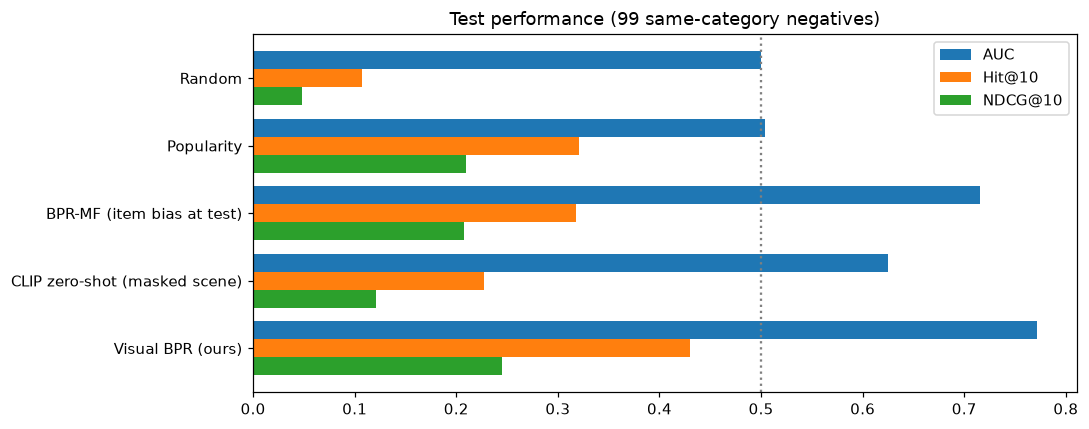

In [15]:
plot = res.drop(index=[i for i in res.index if 'leaky' in i])
plot[['AUC', 'Hit@10', 'NDCG@10']].plot.barh(figsize=(10, 4), width=.8)
plt.axvline(0.5, ls=':', c='grey'); plt.title('Test performance (99 same-category negatives)')
plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

### Breakdown by category and by product popularity

In [16]:
r_vbpr = evaluate(vbpr_score(vbpr), test, NEG_TEST)['_rank']
r_clip = evaluate(cos_score(lambda df: S_MASK[df.row.values]), test, NEG_TEST)['_rank']
br = test.assign(vbpr=r_vbpr < 10, clip=r_clip < 10,
                 seen=np.where(test.p.isin(train_products), 'product seen in train', 'unseen product'))
pd.concat([br.groupby('category')[['clip', 'vbpr']].mean().assign(n=br.category.value_counts()),
           br.groupby('seen')[['clip', 'vbpr']].mean().assign(n=br.seen.value_counts())]
         ).rename(columns={'clip': 'Hit@10 CLIP zero-shot', 'vbpr': 'Hit@10 Visual BPR'}).round(3)

,Hit@10 CLIP zero-shot,Hit@10 Visual BPR,n
Coats & Jackets,0.249,0.400,507
Earrings,0.234,0.269,145
"Handbags, Wallets & Cases",0.172,0.415,621
Necklaces,0.194,0.349,129
Pants,0.212,0.397,1479
Shirts & Tops,0.291,0.447,1201
Shoes,0.237,0.488,2258
Shorts,0.230,0.374,235
Skirts,0.226,0.373,177
Sunglasses,0.095,0.371,402


### Qualitative examples

For random test scenes we show the masked query and the model's top-5 products out of the 100 candidates. The true product is outlined in green.

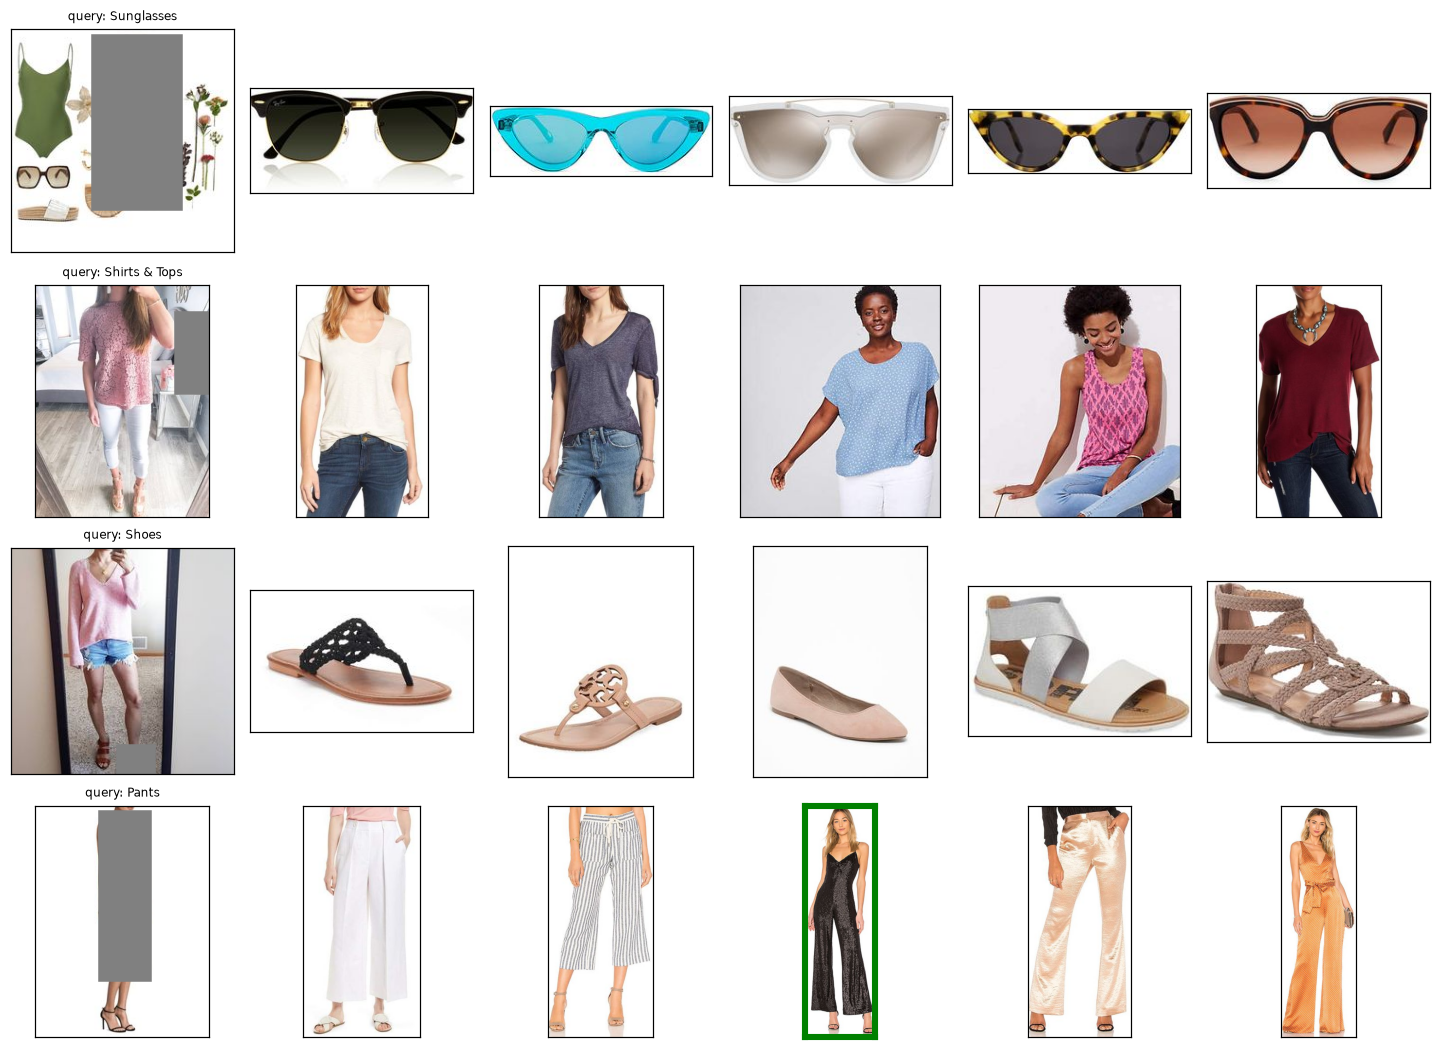

In [17]:
def show_recs(df, neg, score_fn, n=4, top=5, seed=3):
    cand = np.concatenate([df.p.values[:, None], neg], axis=1)
    sc = score_fn(df, cand)
    rows = np.random.default_rng(seed).choice(len(df), n, replace=False)
    fig, ax = plt.subplots(n, top + 1, figsize=(2.2 * (top + 1), 2.4 * n))
    inv_p = idx['products']
    for i, r in enumerate(rows):
        row = df.iloc[r]; im = img(row.scene); w, h = im.size; l, t, rr, b = row.bbox
        ax[i, 0].imshow(im); ax[i, 0].add_patch(plt.Rectangle((l*w, t*h), (rr-l)*w, (b-t)*h, color='grey'))
        ax[i, 0].set_title(f'query: {row.category}', fontsize=8)
        for j, k in enumerate(np.argsort(-sc[r])[:top]):
            ax[i, j + 1].imshow(img(inv_p[cand[r, k]]))
            if k == 0:
                for s in ax[i, j + 1].spines.values(): s.set(color='green', lw=4)
        for a in ax[i]: a.set_xticks([]); a.set_yticks([])
    plt.tight_layout(); plt.show()

show_recs(test, NEG_TEST, vbpr_score(vbpr))

## 5. Related work

* **Complete the Look** (Kang et al., CVPR 2019) introduced this dataset. It combines global scene–product compatibility with *local* attention over scene regions,
  trained with a hinge ranking loss on ResNet features, and evaluated with AUC and Hit@K against same-category negatives.
* **VBPR** (He & McAuley, AAAI 2016) adds visual features to BPR matrix factorisation, which helps with cold-start items. Our Visual BPR follows this idea.
* **BPR** (Rendle et al., UAI 2009): pairwise learning from implicit feedback.
* **Fashion compatibility:** Siamese / metric-learning approaches on Polyvore outfits (e.g. Veit et al. 2015; Vasileva et al. 2018) learn type-aware compatibility spaces.
* **Industry:** Pinterest's production systems (e.g. PinSage, KDD 2018) learn item embeddings from the pin–board graph plus visual and text features, and serve them with approximate nearest-neighbour retrieval.

*TODO (teammate): compare our numbers with those reported in CTL, and add an error analysis.*